<a href="https://colab.research.google.com/github/martinkim1/KANT/blob/main/26/11/11_12_TIL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

data = {
    'user_id': ['U001', 'U002', 'U003', 'U004',
                'U005', 'U006', 'U007', 'U008',
                'U009', 'U010'],
    'age': [20, 25, 30, 35, 40, 45, 50, 55, 60, 65],
    'revenue': [10000, 20000, 15000, 30000, 25000,
                50000, 12000, 45000, 32000, 60000],
    'cost': [5000, 7000, 3000, 12000, 4000,
             15000, 2000, 9000, 6000, 10000]
}

df = pd.DataFrame(data)
df

,user_id,age,revenue,cost
0,U001,20,10000,5000
1,U002,25,20000,7000
2,U003,30,15000,3000
3,U004,35,30000,12000
4,U005,40,25000,4000
5,U006,45,50000,15000
6,U007,50,12000,2000
7,U008,55,45000,9000
8,U009,60,32000,6000
9,U010,65,60000,10000


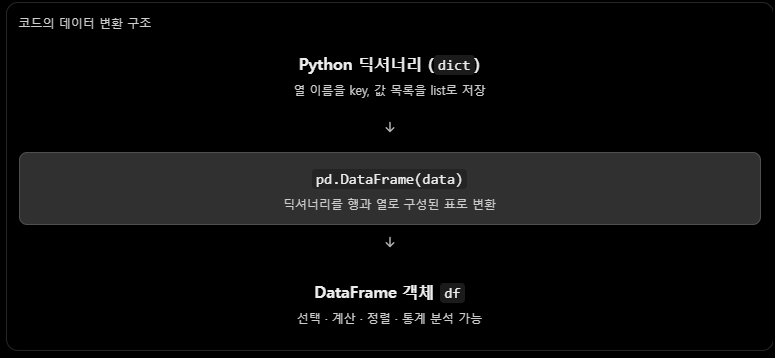

- dict : key와 value가 있는 list 생성
- DataFrame : 행과 열이 있는 표를 생성

In [4]:
revenue = df['revenue']
print(revenue)

0    10000
1    20000
2    15000
3    30000
4    25000
5    50000
6    12000
7    45000
8    32000
9    60000
Name: revenue, dtype: int64


In [6]:
age_counts = df['age'].value_counts() # value_counts()는 Series에 들어있는 고유값들이 몇 번 등장하는지 카운트하는 함수.
print(age_counts)
'''
나이에 겹치는 값이 없어서 빈도 분석으로는 특별한 패턴 분석이 어려움.
따라서 pd.cut() 메서드로 구간별 범주형 데이터로 변환하여 구간화(binning)
'''
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 29, 39, 49, 59, 100],
    labels=['20대 이하', '30대', '40대', '50대', '60대 이상']
)

df['age_group'].value_counts().sort_index()

age
20    1
25    1
30    1
35    1
40    1
45    1
50    1
55    1
60    1
65    1
Name: count, dtype: int64


,count
age_group,
20대 이하,2
30대,2
40대,2
50대,2
60대 이상,2


In [11]:
new_df = df.assign(                    # assign() : 기존 데이터프레임에 열을 추가한 새로운 데이터프레임을 반환
    profit=df['revenue'] - df['cost']
)
new_df

,user_id,age,revenue,cost,age_group,profit
0,U001,20,10000,5000,20대 이하,5000
1,U002,25,20000,7000,20대 이하,13000
2,U003,30,15000,3000,30대,12000
3,U004,35,30000,12000,30대,18000
4,U005,40,25000,4000,40대,21000
5,U006,45,50000,15000,40대,35000
6,U007,50,12000,2000,50대,10000
7,U008,55,45000,9000,50대,36000
8,U009,60,32000,6000,60대 이상,26000
9,U010,65,60000,10000,60대 이상,50000


#### U002와 U003의 revenue(수익)의 차이는 5000원으로 002가 더 좋은 실적을 낸것처럼 보이지만, profit은 1000원 차이로 큰 차이는 없음.
### 분석 목적에 맞게 기존 변수들을 조합하여 새로운 의미 있는 변수를 만드는 것이 특성 공학(Feature Engineering)의 기초.

In [12]:
df_without_cost = new_df.drop('cost', axis=1)
df_without_cost

,user_id,age,revenue,age_group,profit
0,U001,20,10000,20대 이하,5000
1,U002,25,20000,20대 이하,13000
2,U003,30,15000,30대,12000
3,U004,35,30000,30대,18000
4,U005,40,25000,40대,21000
5,U006,45,50000,40대,35000
6,U007,50,12000,50대,10000
7,U008,55,45000,50대,36000
8,U009,60,32000,60대 이상,26000
9,U010,65,60000,60대 이상,50000


In [13]:
df_dropped_rows = new_df.drop([0, 2], axis = 0)
df_dropped_rows

,user_id,age,revenue,cost,age_group,profit
1,U002,25,20000,7000,20대 이하,13000
3,U004,35,30000,12000,30대,18000
4,U005,40,25000,4000,40대,21000
5,U006,45,50000,15000,40대,35000
6,U007,50,12000,2000,50대,10000
7,U008,55,45000,9000,50대,36000
8,U009,60,32000,6000,60대 이상,26000
9,U010,65,60000,10000,60대 이상,50000


### 💡 `drop` 메서드의 축(axis) 개념 정리
- `axis=0` (또는 생략): 리스트 안의 값들을 **행 인덱스 이름**으로 인식하여 해당 행을 통째로 삭제합니다.
- `axis=1`: 리스트 안의 값들을 **열(컬럼) 이름**으로 인식하여 해당 열을 통째로 삭제합니다.

In [15]:
# 1. axis를 생략해도 결과는 같습니다 (기본값이 axis=0 이기 때문)
df_dropped_default = new_df.drop([0, 2])
print("--- axis 생략 시 (행 인덱스 0, 2 삭제) ---")
display(df_dropped_default.head(3))

# 2. 특정 위치(예: 0행의 2번째 열인 'revenue')의 값을 지우고(비우고) 싶을 때
# pandas에서는 '삭제'라기보다 NaN(결측치)이나 빈 값으로 '변경'하는 방식을 사용합니다.
df_modified_value = new_df.copy()
# iloc[행_인덱스_번호, 열_인덱스_번호]를 사용해 특정 원소 지정
df_modified_value.iloc[0, 2] = None
print("\n--- 0행 2열(revenue)의 값을 None으로 변경한 결과 ---")
display(df_modified_value.head(3))

--- axis 생략 시 (행 인덱스 0, 2 삭제) ---


,user_id,age,revenue,cost,age_group,profit
1,U002,25,20000,7000,20대 이하,13000
3,U004,35,30000,12000,30대,18000
4,U005,40,25000,4000,40대,21000



--- 0행 2열(revenue)의 값을 None으로 변경한 결과 ---


,user_id,age,revenue,cost,age_group,profit
0,U001,20,NaN,5000,20대 이하,5000
1,U002,25,20000.0,7000,20대 이하,13000
2,U003,30,15000.0,3000,30대,12000


<Axes: >

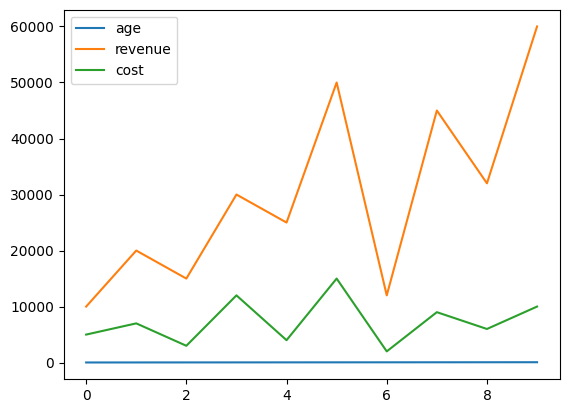

In [19]:
df.plot()

In [20]:
df_sorted_by_age = df.sort_values(by='age', ascending=False) # sort_values(by = '속성', ascending=false) 특정열을 내림차순정렬
df_sorted_by_age

,user_id,age,revenue,cost,age_group
9,U010,65,60000,10000,60대 이상
8,U009,60,32000,6000,60대 이상
7,U008,55,45000,9000,50대
6,U007,50,12000,2000,50대
5,U006,45,50000,15000,40대
4,U005,40,25000,4000,40대
3,U004,35,30000,12000,30대
2,U003,30,15000,3000,30대
1,U002,25,20000,7000,20대 이하
0,U001,20,10000,5000,20대 이하


In [21]:
df['mean'] = df.mean(axis=1, numeric_only = True)
df
'''
mean()모든 열의 평균을 계산
나이와 금액은 단위가 다르기 때문에 이 평균이 무엇을 의미하는지 설명하기 어려움.
코드가 오류 없이 실행된다는 사실과 분석 결과가 의미 있다는 사실은 서로 다르다.
'''

,user_id,age,revenue,cost,age_group,mean
0,U001,20,10000,5000,20대 이하,5006.666667
1,U002,25,20000,7000,20대 이하,9008.333333
2,U003,30,15000,3000,30대,6010.000000
3,U004,35,30000,12000,30대,14011.666667
4,U005,40,25000,4000,40대,9680.000000
5,U006,45,50000,15000,40대,21681.666667
6,U007,50,12000,2000,50대,4683.333333
7,U008,55,45000,9000,50대,18018.333333
8,U009,60,32000,6000,60대 이상,12686.666667
9,U010,65,60000,10000,60대 이상,23355.000000


In [23]:
new_df['profit_margin'] = (
    new_df['profit'] / new_df['revenue']
) * 100
new_df

,user_id,age,revenue,cost,age_group,profit,profit_margin
0,U001,20,10000,5000,20대 이하,5000,50.000000
1,U002,25,20000,7000,20대 이하,13000,65.000000
2,U003,30,15000,3000,30대,12000,80.000000
3,U004,35,30000,12000,30대,18000,60.000000
4,U005,40,25000,4000,40대,21000,84.000000
5,U006,45,50000,15000,40대,35000,70.000000
6,U007,50,12000,2000,50대,10000,83.333333
7,U008,55,45000,9000,50대,36000,80.000000
8,U009,60,32000,6000,60대 이상,26000,81.250000
9,U010,65,60000,10000,60대 이상,50000,83.333333


In [27]:
test = {
    'ID(1열)' : ['U001', 'U002', 'U003'],
    'P.W(2열)' : ['1234', 'qwer', '0703'],
    '이름(3열)' : ['김동연', '홍길동', '따띠']
}
test

{'ID(1열)': ['U001', 'U002', 'U003'],
 'P.W(2열)': ['1234', 'qwer', '0703'],
 '이름(3열)': ['김동연', '홍길동', '따띠']}

In [28]:
test_df = pd.DataFrame(test)
test_df

,ID(1열),P.W(2열),이름(3열)
0,U001,1234,김동연
1,U002,qwer,홍길동
2,U003,0703,따띠


In [30]:
test_df['주소'] = ['동대문구', '성동구', '중구']
test_df

,ID(1열),P.W(2열),이름(3열),주소
0,U001,1234,김동연,동대문구
1,U002,qwer,홍길동,성동구
2,U003,0703,따띠,중구


In [32]:
test_df2= test_df.assign(
    test = test_df['ID(1열)'] + test_df['P.W(2열)']
)
test_df2

,ID(1열),P.W(2열),이름(3열),주소,test
0,U001,1234,김동연,동대문구,U0011234
1,U002,qwer,홍길동,성동구,U002qwer
2,U003,0703,따띠,중구,U0030703


In [35]:
new_df.drop('cost', axis=1, inplace=True) # inplace=True : 원본도 같이 제거.

KeyError: "['cost'] not found in axis"

In [36]:
new_df

,user_id,age,revenue,age_group,profit,profit_margin
0,U001,20,10000,20대 이하,5000,50.000000
1,U002,25,20000,20대 이하,13000,65.000000
2,U003,30,15000,30대,12000,80.000000
3,U004,35,30000,30대,18000,60.000000
4,U005,40,25000,40대,21000,84.000000
5,U006,45,50000,40대,35000,70.000000
6,U007,50,12000,50대,10000,83.333333
7,U008,55,45000,50대,36000,80.000000
8,U009,60,32000,60대 이상,26000,81.250000
9,U010,65,60000,60대 이상,50000,83.333333


In [37]:
import pandas as pd

df = pd.DataFrame({
    'name': ['Kim', 'Lee', 'Park'],
    'age': [20, 25, 30],
    'score': [80, 90, 70]
})

df2 = df.drop('score', axis=1)
df3 = df2.drop([0], axis=0)

In [42]:
df3

,name,age
1,Lee,25
2,Park,30
